In [15]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv


In [16]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv')

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [17]:
print(df.shape)
print(df.info())

(398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB
None


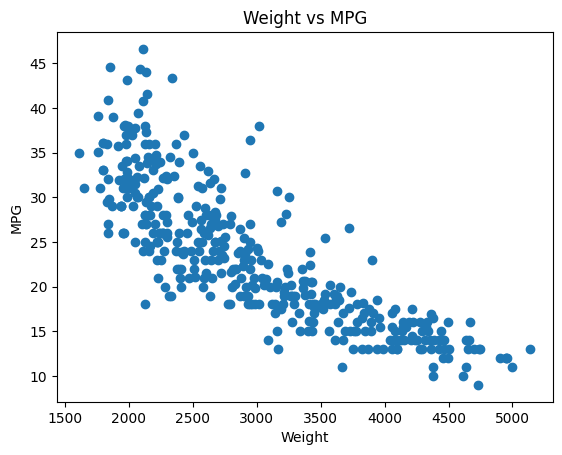

In [18]:
import matplotlib.pyplot as plt

plt.scatter(df['weight'], df['mpg'])
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.title('Weight vs MPG')
plt.show()


In [19]:
X = df[['weight']].values
y = df['mpg'].values

print(X.shape)
print(y.shape)

(398, 1)
(398,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(318, 1)
(80, 1)


In [21]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(X_train_poly.shape)
print(X_test_poly.shape)


(318, 3)
(80, 3)


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train_poly.copy()
X_test_scaled = X_test_poly.copy()

X_train_scaled[:, 1:] = scaler.fit_transform(X_train_poly[:, 1:])
X_test_scaled[:, 1:] = scaler.transform(X_test_poly[:, 1:])

In [23]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(318, 3)
(80, 3)


In [24]:
# Initialize parameters
import numpy as np
weights = np.zeros(X_train_scaled.shape[1])
velocity = np.zeros(X_train_scaled.shape[1])

# Hyperparameters
learning_rate = 0.001
momentum = 0.9
epochs = 1000

n = len(y_train)
loss_history = []

# Training
for epoch in range(epochs):

    for i in range(n):

        x_i = X_train_scaled[i]
        y_i = y_train[i]

        prediction = x_i @ weights
        error = prediction - y_i

        gradient = 2 * x_i * error

        velocity = momentum * velocity + gradient
        weights = weights - learning_rate * velocity

    predictions = X_train_scaled @ weights
    loss = np.mean((predictions - y_train) ** 2)
    loss_history.append(loss)

print("Final Training MSE:", loss_history[-1])

Final Training MSE: 18.508997280943404


In [25]:
y_pred = X_test_scaled @ weights

test_mse = np.mean((y_test - y_pred) ** 2)

print("Test MSE:", test_mse)

Test MSE: 13.390649537283025


In [29]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

R2 Score: 0.750947829104226


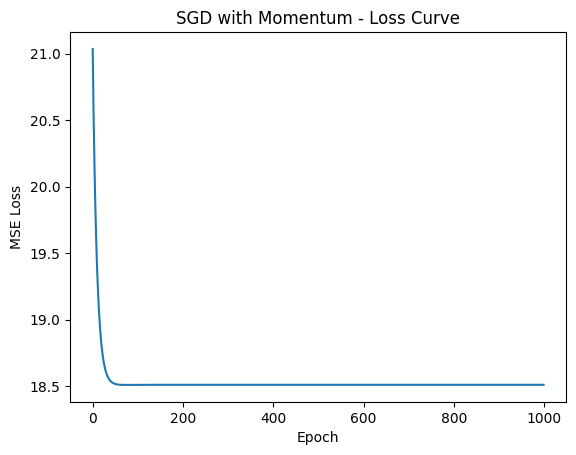

In [30]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("SGD with Momentum - Loss Curve")
plt.show()